# 01 — Data overview, visualization and file checks

This is the first notebook of the classification pipeline. It:

1. discovers the classes and image files;
2. checks that every image is readable and records its dimensions;
3. visualizes the class distribution and some sample images;
4. creates a stratified **train / validation / test** split and saves it to
   `data/processed/splits.json`.

The next notebooks reuse the saved split, so you only need to run this
notebook once (or again whenever the dataset changes).


## 1. Imports and project paths

Imports the libraries used throughout the notebook and resolves `ROOT_DIR`
so the file works whether Jupyter is started from the repository root or
from the `notebooks/` folder.

**How to read the output:** the three printed paths must point to the project
root, `data/Data` (raw images) and `data/processed` (generated files). If
they look wrong, fix `ROOT_DIR` before running anything else.

In [1]:
from pathlib import Path
from collections import Counter
import json
import random

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Work from the project root whether the notebook is launched from the
# repository root or from the notebooks/ directory.
ROOT_DIR = Path.cwd()
if ROOT_DIR.name == "notebooks":
    ROOT_DIR = ROOT_DIR.parent

DATA_DIR = ROOT_DIR / "data" / "Data"
PROCESSED_DIR = ROOT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

VALID_EXTENSIONS = (".jpeg", ".jpg", ".png", ".bmp")
IMG_SIZE = (224, 224)
SEED = 42

print("Project root :", ROOT_DIR)
print("Data dir     :", DATA_DIR)
print("Processed dir:", PROCESSED_DIR)


Project root : /home/fangyuan/Projects/Diagnostic-des-tumeurs
Data dir     : /home/fangyuan/Projects/Diagnostic-des-tumeurs/data/Data
Processed dir: /home/fangyuan/Projects/Diagnostic-des-tumeurs/data/processed


## 2. Discover the classes

Lists the sub-folders of `data/Data`. Each folder name becomes a class and
receives an integer id in alphabetical order.

**How to read the output:** you should see exactly the expected diagnosis
classes (for example `glioma`, `meningioma`, `notumor`, `pituitary`). A
missing or extra folder here would silently change the labels used by every
later notebook.

In [2]:
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset directory not found: {DATA_DIR}\n"
        "Expected a folder such as data/Data/glioma/*.jpg"
    )

classes = sorted(d.name for d in DATA_DIR.iterdir() if d.is_dir())
class_to_id = {name: i for i, name in enumerate(classes)}
id_to_class = {i: name for name, i in class_to_id.items()}

print("Classes :", classes)
print("Mapping :", class_to_id)


Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']
Mapping : {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


## 3. Collect image paths and labels

Walks every class folder, keeps files with a valid image extension and builds
one DataFrame row per image with its path and integer label.

**How to read the output:** `Total images` is the size of the dataset and the
preview table shows the path, the label, the class name and the file size.
Unusually small files are often truncated or corrupt images.

In [3]:
def load_data(path: Path, classes: list[str], class_to_id: dict) -> tuple[list[Path], list[int]]:
    """Return every valid image path and its integer label."""
    paths, labels = [], []
    for class_name in classes:
        class_dir = path / class_name
        for file in sorted(class_dir.iterdir()):
            if file.is_file() and file.suffix.lower() in VALID_EXTENSIONS:
                paths.append(file)
                labels.append(class_to_id[class_name])
    return paths, labels


data_paths, data_labels = load_data(DATA_DIR, classes, class_to_id)

df = pd.DataFrame({
    "path": [str(p) for p in data_paths],
    "label": data_labels,
})
df["class_name"] = df["label"].map(id_to_class)
df["file_size_kb"] = df["path"].map(lambda p: Path(p).stat().st_size / 1024)

print(f"Total images: {len(df)}")
df.head()


Total images: 7023


,path,label,class_name,file_size_kb
0,/home/fangyuan/Projects/Diagnostic-des-tumeurs...,0,glioma,25.220703
1,/home/fangyuan/Projects/Diagnostic-des-tumeurs...,0,glioma,20.490234
2,/home/fangyuan/Projects/Diagnostic-des-tumeurs...,0,glioma,12.973633
3,/home/fangyuan/Projects/Diagnostic-des-tumeurs...,0,glioma,25.524414
4,/home/fangyuan/Projects/Diagnostic-des-tumeurs...,0,glioma,21.200195


## 4. Class distribution

Counts the images per class and computes the imbalance ratio
(largest class / smallest class).

**How to read the output:** compare the counts below with the charts in the
next cell. A ratio close to `1` means the dataset is balanced; a large ratio
means some classes are seen much less often during training, which is why
notebook 02 oversamples the minority classes.

In [4]:
class_counts = df["class_name"].value_counts().reindex(classes)
print(class_counts.to_string())
print("\nTotal          :", int(class_counts.sum()))
print("Imbalance ratio:", round(float(class_counts.max() / class_counts.min()), 3))


class_name
glioma        1621
meningioma    1645
notumor       2000
pituitary     1757

Total          : 7023
Imbalance ratio: 1.234


## 5. Visualize the class distribution

Draws a bar chart (absolute counts) and a pie chart (proportions) of the class
counts.

**How to read the output:** the two charts show the same information in two
ways. Use them to spot under-represented classes before any balancing step.

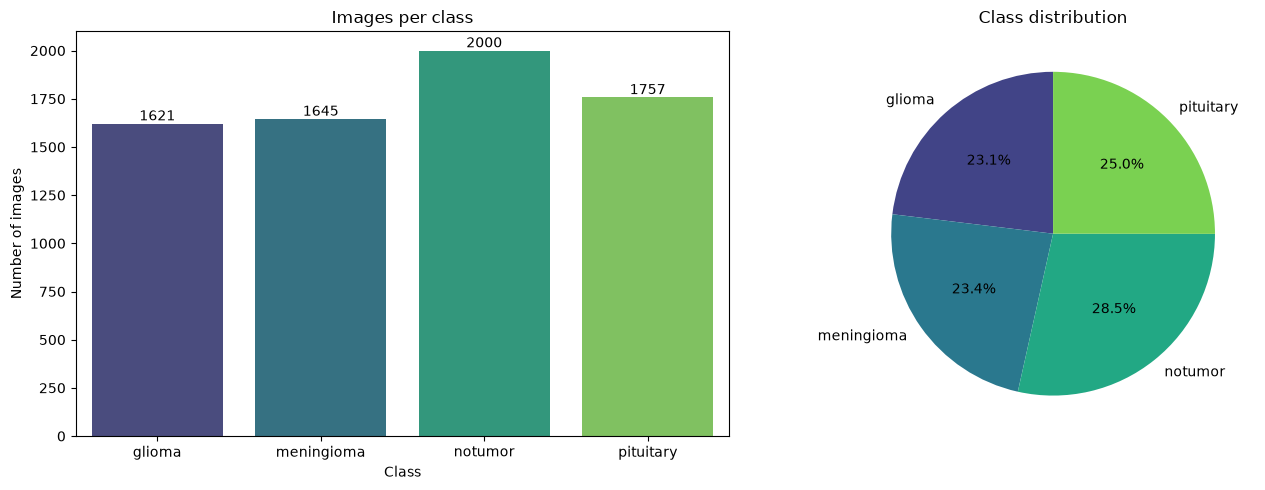

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    hue=class_counts.index,
    palette="viridis",
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Images per class")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of images")
for i, value in enumerate(class_counts.values):
    axes[0].text(i, value, str(int(value)), ha="center", va="bottom")

axes[1].pie(
    class_counts.values,
    labels=class_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("viridis", len(classes)),
)
axes[1].set_title("Class distribution")

plt.tight_layout()
plt.show()


## 6. Check readability, channels and resolution

Reads every image with OpenCV and records whether it is readable, plus its
width, height and number of channels.

**How to read the output:** `Unreadable files` should be `0`, `Channel counts`
should be `3` (RGB) for every image, and the resolution table shows whether
the dataset is homogeneous. Notebook 02 resizes everything to 224x224, but
this check is what proves the files are actually usable.

In [6]:
def inspect_image(path: str) -> dict:
    """Read an image header and return its dimensions and channel count."""
    image = cv2.imread(path)
    if image is None:
        return {
            "path": path,
            "readable": False,
            "width": None,
            "height": None,
            "channels": None,
        }
    height, width = image.shape[:2]
    channels = image.shape[2] if image.ndim == 3 else 1
    return {
        "path": path,
        "readable": True,
        "width": width,
        "height": height,
        "channels": channels,
    }


metadata = pd.DataFrame([inspect_image(p) for p in df["path"]])
df = df.merge(metadata, on="path", how="left")

print("Unreadable files:", int((~df["readable"]).sum()))
print("\nChannel counts:")
print(df["channels"].value_counts(dropna=False).to_string())
print("\nMost common resolutions (width x height):")
print(df.groupby(["width", "height"]).size().sort_values(ascending=False).head(10).to_string())


Unreadable files: 0

Channel counts:
channels
3    7023

Most common resolutions (width x height):
width  height
512    512       4742
225    225        332
630    630         90
236    236         81
201    251         58
228    221         51
232    217         50
300    168         49
442    442         46
150    198         44


## 7. List unreadable files

Displays the rows that the previous cell flagged as unreadable.

**How to read the output:** `All images are readable.` is the expected result.
If a table appears instead, delete or repair those files before creating the
split, otherwise training will crash when it tries to load them.

In [7]:
if (~df["readable"]).any():
    print("Files that could not be read:")
    display(df.loc[~df["readable"], ["path", "class_name"]])
else:
    print("All images are readable.")


All images are readable.


## 8. Most common resolutions

Plots the ten most frequent `width x height` combinations.

**How to read the output:** one dominant resolution means the dataset was
pre-resized; many resolutions mean images come from different sources. No
action is needed, because preprocessing resizes every image to 224x224.

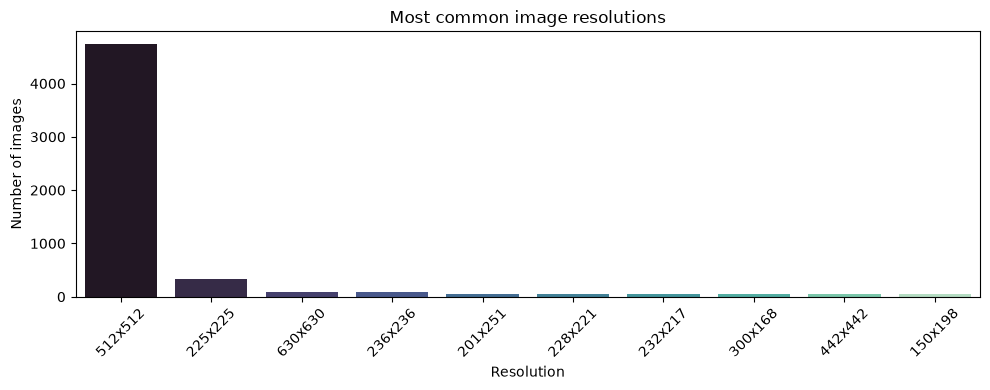

In [8]:
resolution_counts = (
    df.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 4))
sns.barplot(
    x=[f"{w}x{h}" for w, h in resolution_counts.index],
    y=resolution_counts.values,
    hue=[f"{w}x{h}" for w, h in resolution_counts.index],
    palette="mako",
    legend=False,
)
plt.title("Most common image resolutions")
plt.xlabel("Resolution")
plt.ylabel("Number of images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 9. Sample images per class

Displays a few random images of each class (seed fixed so the choice is
reproducible).

**How to read the output:** this is a label sanity check: each row should
contain images that really belong to the class written above them.
Mislabeled folders are the most common reason a model cannot learn.

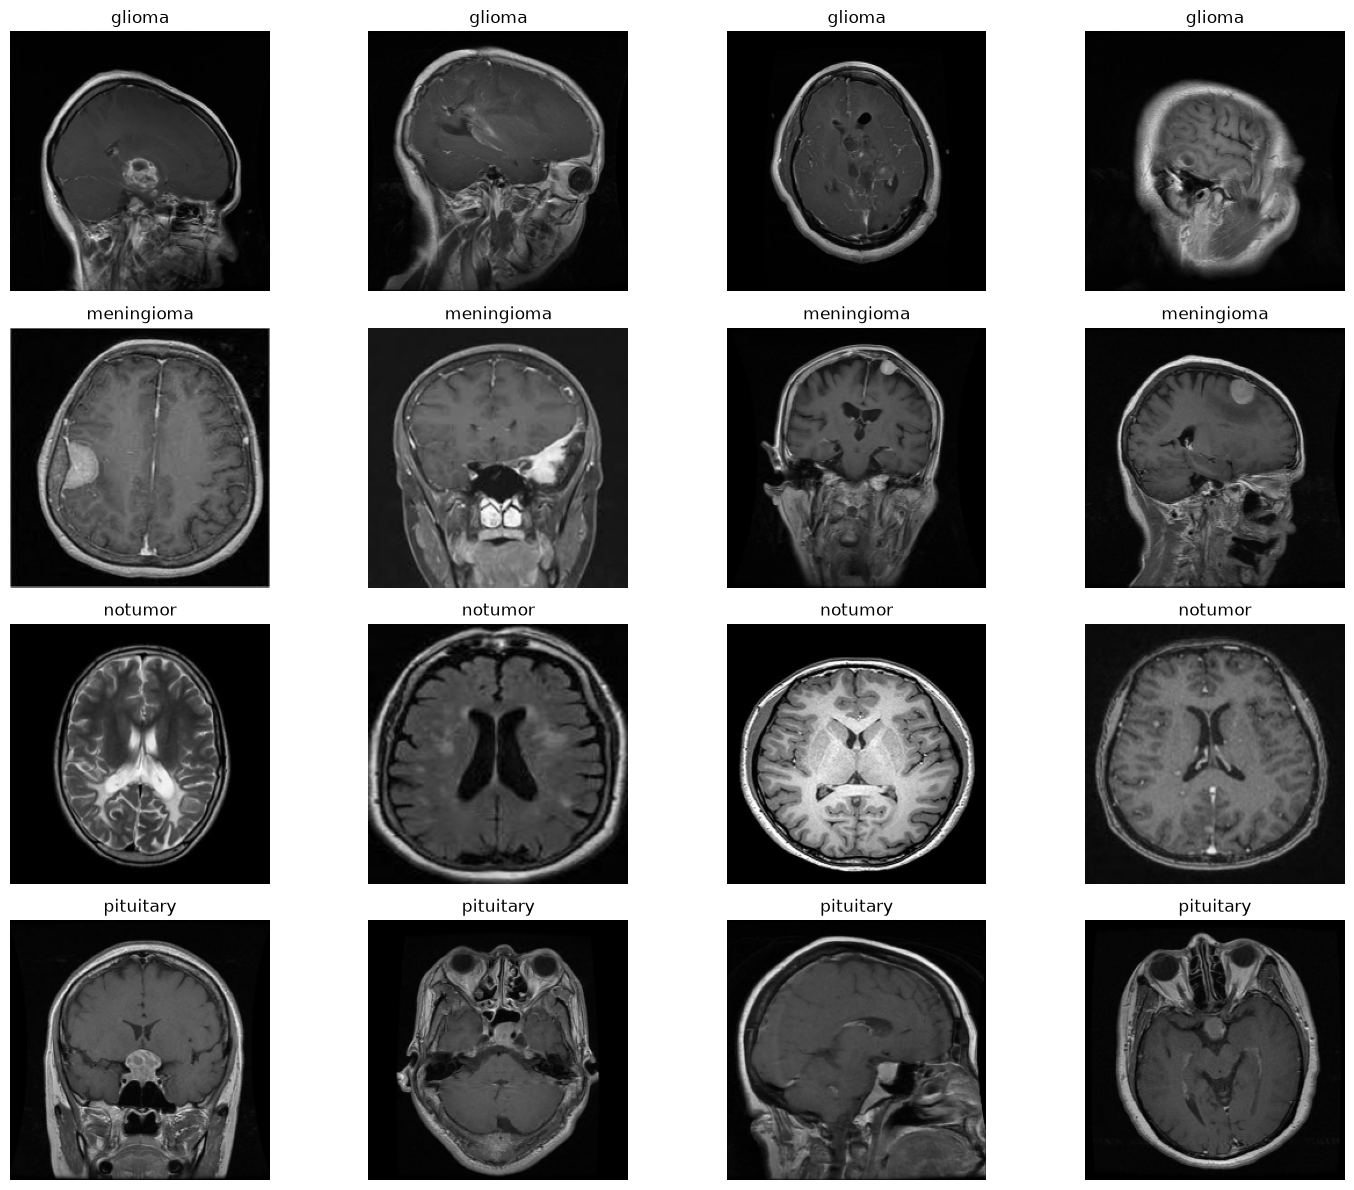

In [9]:
random.seed(SEED)
n_samples = 4

fig, axes = plt.subplots(len(classes), n_samples, figsize=(15, 3 * len(classes)))
axes = np.atleast_2d(axes)

for row, class_name in enumerate(classes):
    class_paths = df.loc[df["class_name"] == class_name, "path"].tolist()
    samples = random.sample(class_paths, min(n_samples, len(class_paths)))

    for col in range(n_samples):
        ax = axes[row, col]
        if col < len(samples):
            image = cv2.imread(samples[col])
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            image = cv2.resize(image, IMG_SIZE)
            ax.imshow(image)
            ax.set_title(class_name)
        ax.axis("off")

plt.tight_layout()
plt.show()


## 10. Stratified train / validation / test split

Splits the images with `train_test_split` while keeping the same class
proportions in every subset: 70% train, 15% validation, 15% test.

**How to read the output:** the three counts should roughly follow 70/15/15
and add up to the total number of images. The test set is only used at the
very end to measure final performance, never during training.

In [10]:
# Stratified 70% train / 15% validation / 15% test split.
X_train, X_temp, y_train, y_temp = train_test_split(
    data_paths,
    data_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=data_labels,
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp,
)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")


Train: 4916 | Val: 1053 | Test: 1054


## 11. Save the split and the image metadata

Writes `data/processed/splits.json` (paths and labels for the three subsets)
and `data/processed/image_metadata.csv` (the per-image checks from step 6).

**How to read the output:** both file paths are printed. `splits.json` is the
contract between the four notebooks, so every later notebook reads it. Paths
are stored relative to the project root so the project can be moved.

In [11]:
def relative_path(path: Path) -> str:
    return path.relative_to(ROOT_DIR).as_posix()


splits = {
    "classes": classes,
    "class_to_id": class_to_id,
    "id_to_class": {str(k): v for k, v in id_to_class.items()},
    "img_size": list(IMG_SIZE),
    "seed": SEED,
    "train": {
        "paths": [relative_path(p) for p in X_train],
        "labels": [int(y) for y in y_train],
    },
    "val": {
        "paths": [relative_path(p) for p in X_val],
        "labels": [int(y) for y in y_val],
    },
    "test": {
        "paths": [relative_path(p) for p in X_test],
        "labels": [int(y) for y in y_test],
    },
}

splits_path = PROCESSED_DIR / "splits.json"
with open(splits_path, "w") as f:
    json.dump(splits, f, indent=2)

metadata_path = PROCESSED_DIR / "image_metadata.csv"
df.to_csv(metadata_path, index=False)

print("Saved splits         :", splits_path)
print("Saved image metadata :", metadata_path)


Saved splits         : /home/fangyuan/Projects/Diagnostic-des-tumeurs/data/processed/splits.json
Saved image metadata : /home/fangyuan/Projects/Diagnostic-des-tumeurs/data/processed/image_metadata.csv


## 12. Reload and verify the split

Reads `splits.json` back from disk and prints the number of images per subset.

**How to read the output:** these numbers must match step 10. If they differ,
the file was not written correctly and the later notebooks would train on the
wrong data.

In [12]:
with open(splits_path) as f:
    saved_splits = json.load(f)

print({split: len(saved_splits[split]["paths"]) for split in ("train", "val", "test")})


{'train': 4916, 'val': 1053, 'test': 1054}


## Next step

Open **`02_preprocessing_augmentation.ipynb`**. It loads `data/processed/splits.json`,
defines the image preprocessing and augmentation functions, and creates a
balanced training manifest.
